# 5. Gradiente que se dissipa

Duas redes iguais (6 camadas ocultas de 32, SGD) no MNIST: sigmoid + pesos pequenos provoca o problema; ReLU + He é a referência saudável.

In [23]:
import sys
sys.path.append("..")  # so we can import the code in src/

import numpy as np

from src.datasets import load_mnist
from src.nn import MLP
from src.optim import SGD
from src.training import train
from src.plots import plot_loss, plot_metric, plot_histograms, plot_gradient_sizes

PLOTS = "../assets/plots/"

# Same y axis on the plots of both networks, so they can be compared directly.
LOSS_YLIM = (0, 0.4)

In [24]:
X_train, y_train, X_val, y_val = load_mnist()

X_train = X_train[:10000]
y_train = y_train[:10000]
X_val = X_val[:2000]
y_val = y_val[:2000]

## Rede 1: sigmoid + inicialização normal (std = 0.1)

In [25]:
vanishing_model = MLP(input_size=784, hidden_sizes=[32, 32, 32, 32, 32, 32], output_size=10,
                      hidden_activation="sigmoid", output_activation="sigmoid",
                      init="normal", init_scale=0.1)

optimizer = SGD(vanishing_model.parameters(), lr=0.1)

vanishing_history = train(vanishing_model, optimizer, "bce", X_train, y_train, X_val, y_val,
                          epochs=10, batch_size=32, metric_name="accuracy", print_every=1)

epoch    1 | train loss 0.3250 | val loss 0.3250 | train accuracy 0.1127 | val accuracy 0.1170
epoch    2 | train loss 0.3249 | val loss 0.3249 | train accuracy 0.1127 | val accuracy 0.1170
epoch    3 | train loss 0.3249 | val loss 0.3250 | train accuracy 0.1070 | val accuracy 0.1025
epoch    4 | train loss 0.3249 | val loss 0.3250 | train accuracy 0.1127 | val accuracy 0.1170
epoch    5 | train loss 0.3248 | val loss 0.3250 | train accuracy 0.1127 | val accuracy 0.1170
epoch    6 | train loss 0.3249 | val loss 0.3250 | train accuracy 0.1127 | val accuracy 0.1170
epoch    7 | train loss 0.3249 | val loss 0.3249 | train accuracy 0.1127 | val accuracy 0.1170
epoch    8 | train loss 0.3249 | val loss 0.3249 | train accuracy 0.1127 | val accuracy 0.1170
epoch    9 | train loss 0.3249 | val loss 0.3249 | train accuracy 0.1127 | val accuracy 0.1170
epoch   10 | train loss 0.3248 | val loss 0.3249 | train accuracy 0.1127 | val accuracy 0.1170


A loss não se move e a acurácia fica no acaso (~11%): a rede não aprende.

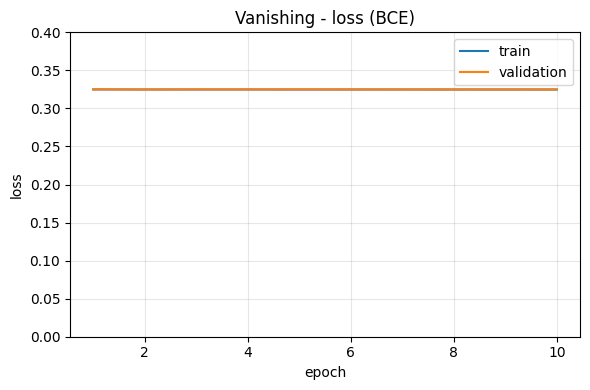

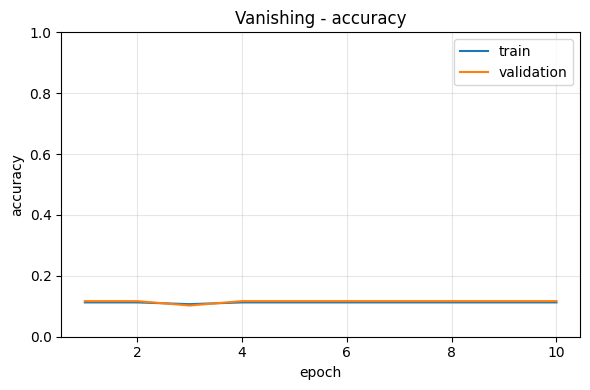

In [26]:
plot_loss(vanishing_history, title="Vanishing - loss (BCE)", save_path=PLOTS + "vanishing_loss.png", ylim=LOSS_YLIM)
plot_metric(vanishing_history, "accuracy", title="Vanishing - accuracy", save_path=PLOTS + "vanishing_accuracy.png", ylim=(0, 1))

O eixo x dos gradientes encolhe várias ordens de grandeza da última camada para a primeira. As ativações viram picos em ~0.5 e não mudam.

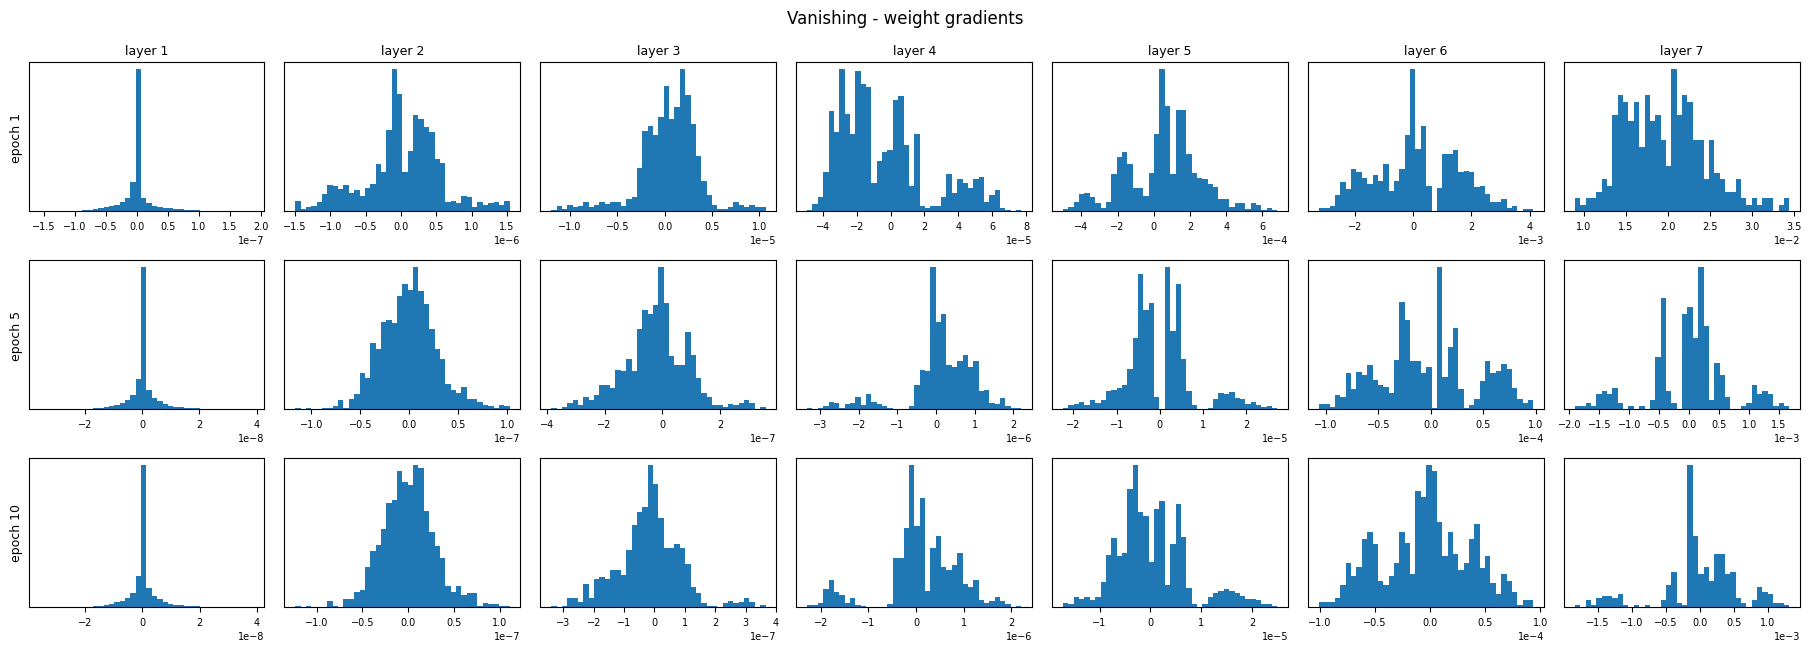

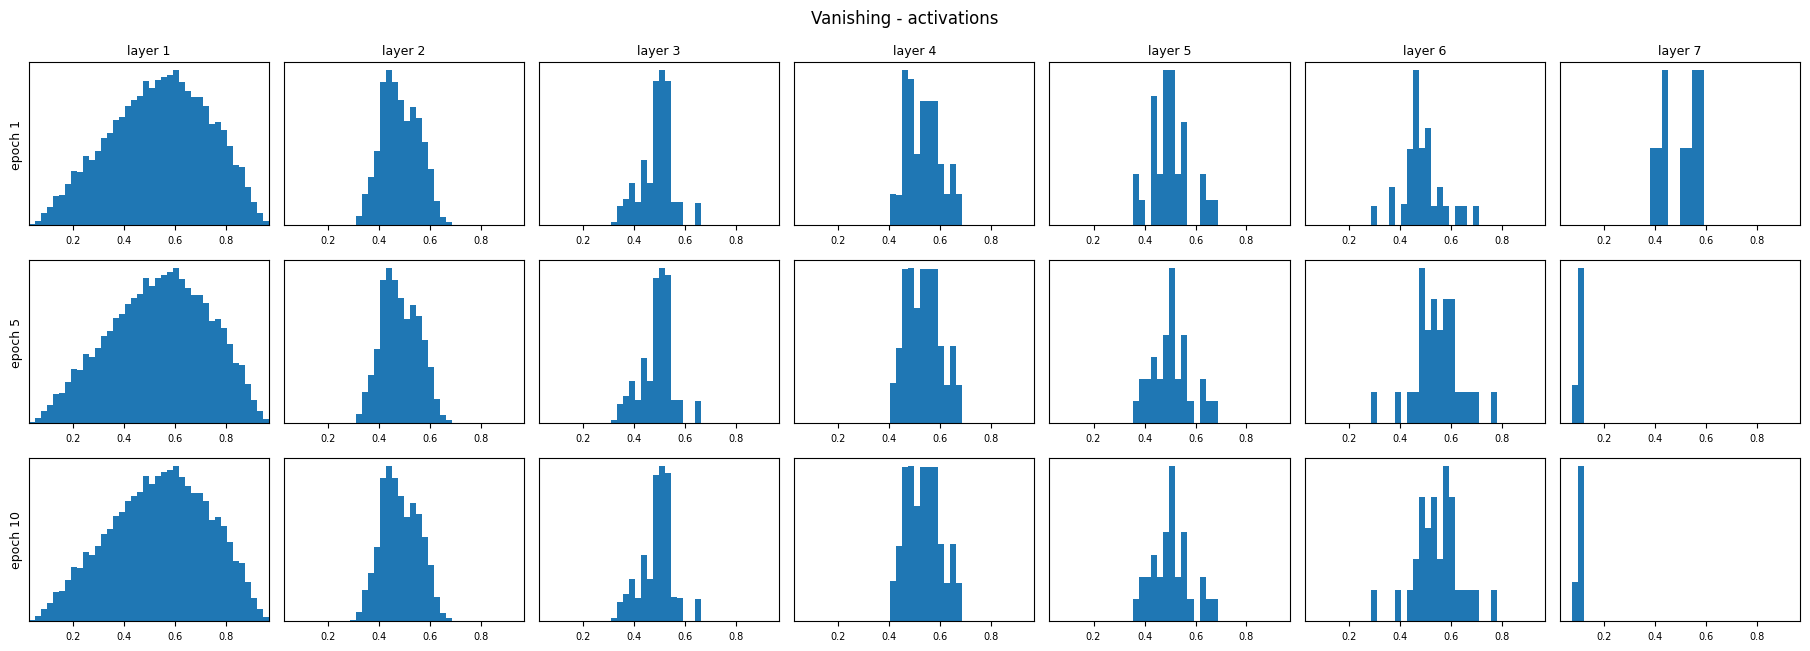

In [27]:
plot_histograms(vanishing_history, "gradients", title="Vanishing - weight gradients", save_path=PLOTS + "vanishing_gradients.png")
plot_histograms(vanishing_history, "activations", title="Vanishing - activations", save_path=PLOTS + "vanishing_activations.png")

Par

In [28]:
vanishing_model2 = MLP(input_size=784, hidden_sizes=[32, 32, 32, 32, 32, 32], output_size=10,
                      hidden_activation="sigmoid", output_activation="sigmoid",
                      init="normal", init_scale=3)

optimizer2 = SGD(vanishing_model2.parameters(), lr=0.1)

vanishing_history2 = train(vanishing_model2, optimizer, "bce", X_train, y_train, X_val, y_val,
                          epochs=10, batch_size=32, metric_name="accuracy", print_every=1)

epoch    1 | train loss 6.2344 | val loss 6.2456 | train accuracy 0.0986 | val accuracy 0.0890
epoch    2 | train loss 6.2344 | val loss 6.2456 | train accuracy 0.0986 | val accuracy 0.0890
epoch    3 | train loss 6.2344 | val loss 6.2456 | train accuracy 0.0986 | val accuracy 0.0890
epoch    4 | train loss 6.2344 | val loss 6.2456 | train accuracy 0.0986 | val accuracy 0.0890
epoch    5 | train loss 6.2344 | val loss 6.2456 | train accuracy 0.0986 | val accuracy 0.0890
epoch    6 | train loss 6.2344 | val loss 6.2456 | train accuracy 0.0986 | val accuracy 0.0890
epoch    7 | train loss 6.2344 | val loss 6.2456 | train accuracy 0.0986 | val accuracy 0.0890
epoch    8 | train loss 6.2344 | val loss 6.2456 | train accuracy 0.0986 | val accuracy 0.0890
epoch    9 | train loss 6.2344 | val loss 6.2456 | train accuracy 0.0986 | val accuracy 0.0890
epoch   10 | train loss 6.2344 | val loss 6.2456 | train accuracy 0.0986 | val accuracy 0.0890


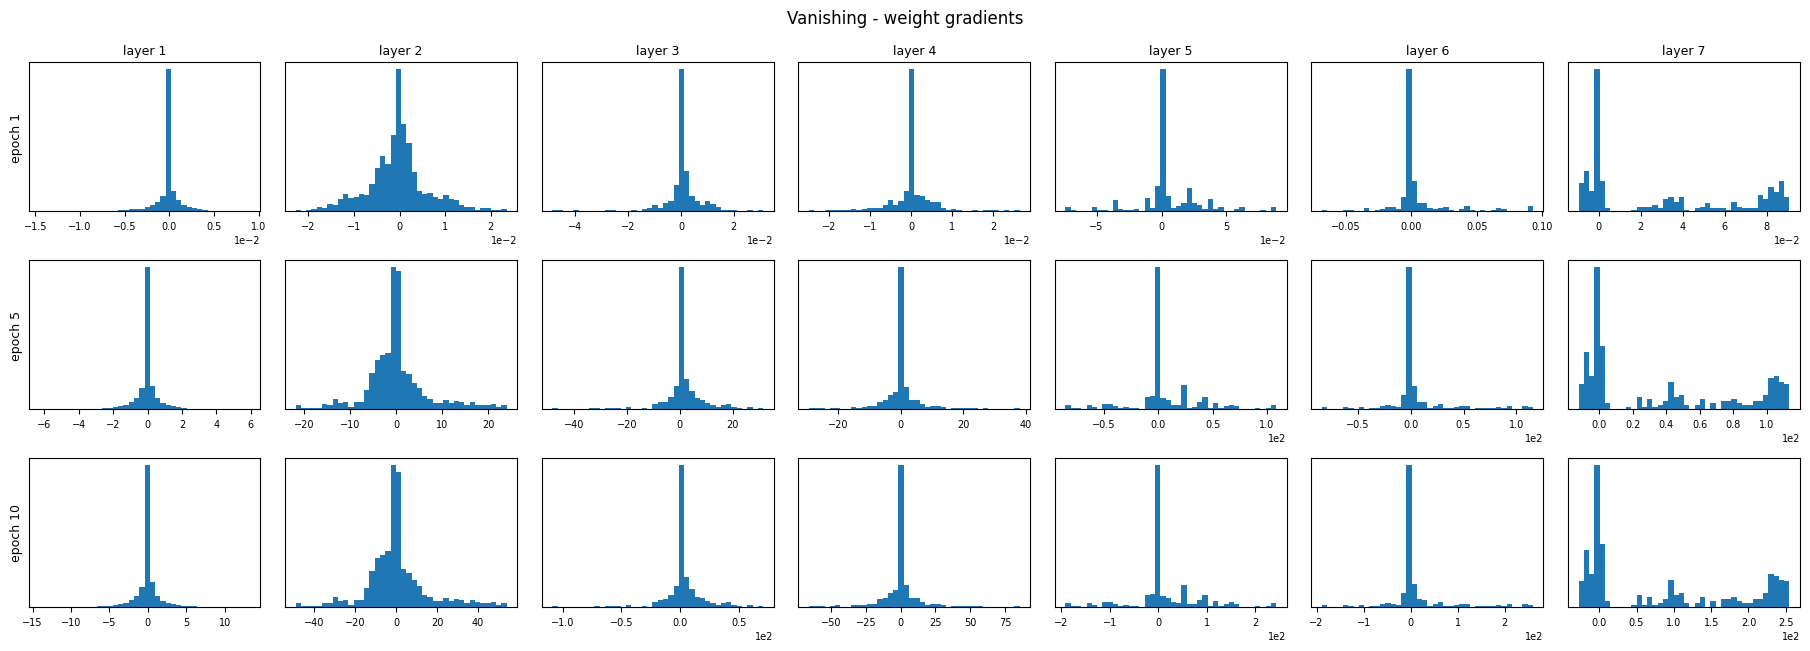

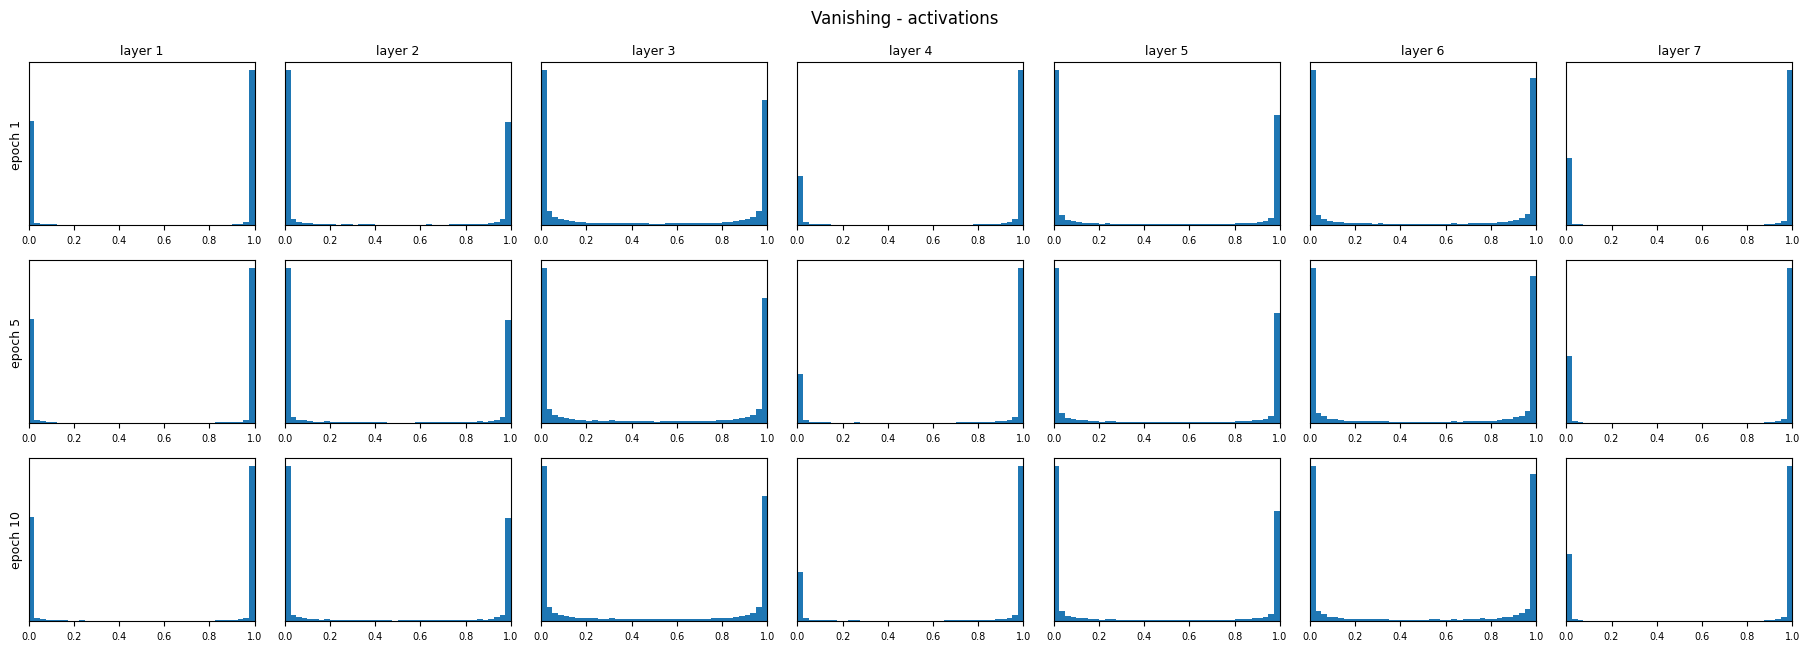

In [29]:
plot_histograms(vanishing_history2, "gradients", title="Vanishing - weight gradients", save_path=PLOTS + "vanishing_gradients2.png")
plot_histograms(vanishing_history2, "activations", title="Vanishing - activations", save_path=PLOTS + "vanishing_activations2.png")

## Rede 2: ReLU + inicialização He

In [30]:
healthy_model = MLP(input_size=784, hidden_sizes=[32, 32, 32, 32, 32, 32], output_size=10,
                    hidden_activation="relu", output_activation="sigmoid", init="he")

optimizer = SGD(healthy_model.parameters(), lr=0.1)

healthy_history = train(healthy_model, optimizer, "bce", X_train, y_train, X_val, y_val,
                        epochs=10, batch_size=32, metric_name="accuracy", print_every=1)

epoch    1 | train loss 0.1438 | val loss 0.1605 | train accuracy 0.7516 | val accuracy 0.7165
epoch    2 | train loss 0.1006 | val loss 0.1227 | train accuracy 0.8337 | val accuracy 0.7955
epoch    3 | train loss 0.0815 | val loss 0.1061 | train accuracy 0.8821 | val accuracy 0.8430
epoch    4 | train loss 0.0598 | val loss 0.0840 | train accuracy 0.9073 | val accuracy 0.8665
epoch    5 | train loss 0.0507 | val loss 0.0772 | train accuracy 0.9248 | val accuracy 0.8790
epoch    6 | train loss 0.0598 | val loss 0.0833 | train accuracy 0.9048 | val accuracy 0.8635
epoch    7 | train loss 0.0618 | val loss 0.0906 | train accuracy 0.8985 | val accuracy 0.8475
epoch    8 | train loss 0.0416 | val loss 0.0760 | train accuracy 0.9357 | val accuracy 0.8755
epoch    9 | train loss 0.0325 | val loss 0.0615 | train accuracy 0.9525 | val accuracy 0.9035
epoch   10 | train loss 0.0386 | val loss 0.0725 | train accuracy 0.9411 | val accuracy 0.8795


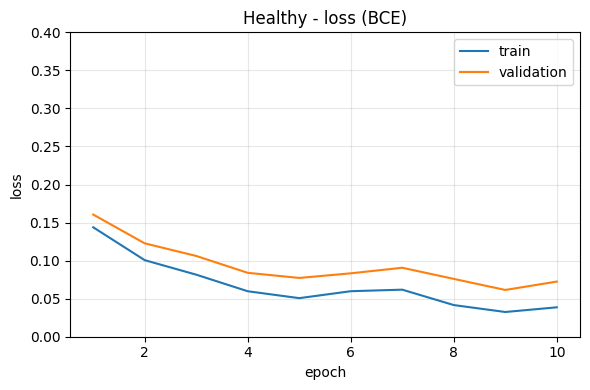

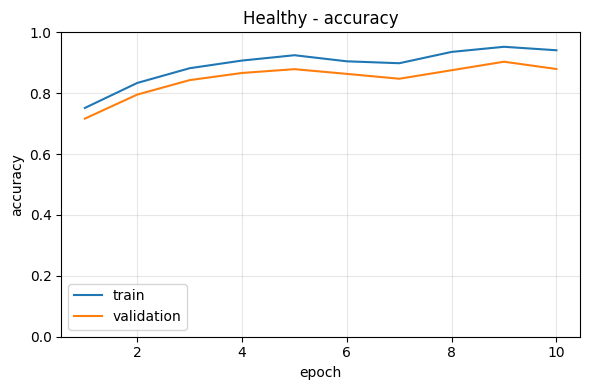

In [31]:
plot_loss(healthy_history, title="Healthy - loss (BCE)", save_path=PLOTS + "healthy_loss.png", ylim=LOSS_YLIM)
plot_metric(healthy_history, "accuracy", title="Healthy - accuracy", save_path=PLOTS + "healthy_accuracy.png", ylim=(0, 1))

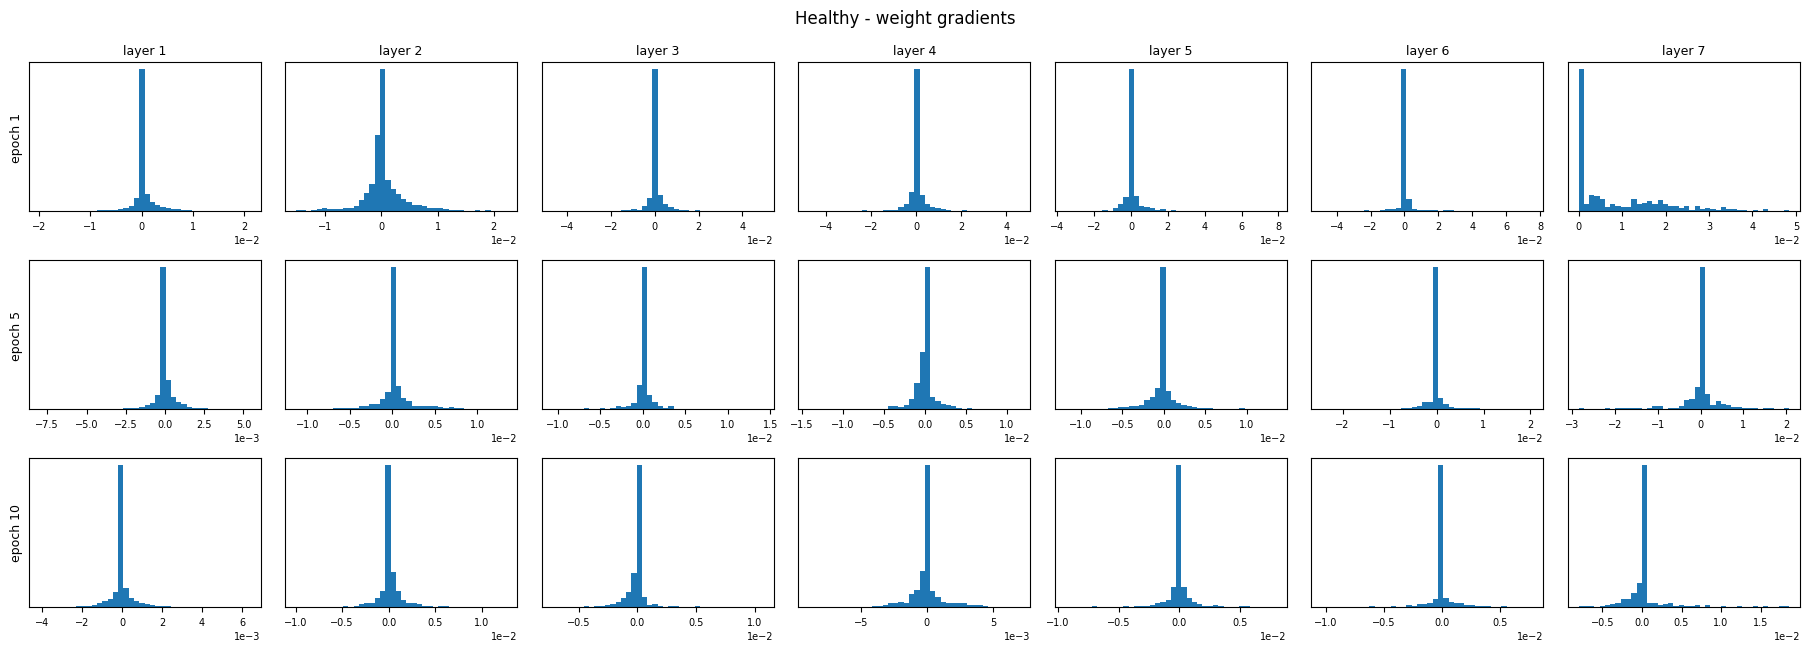

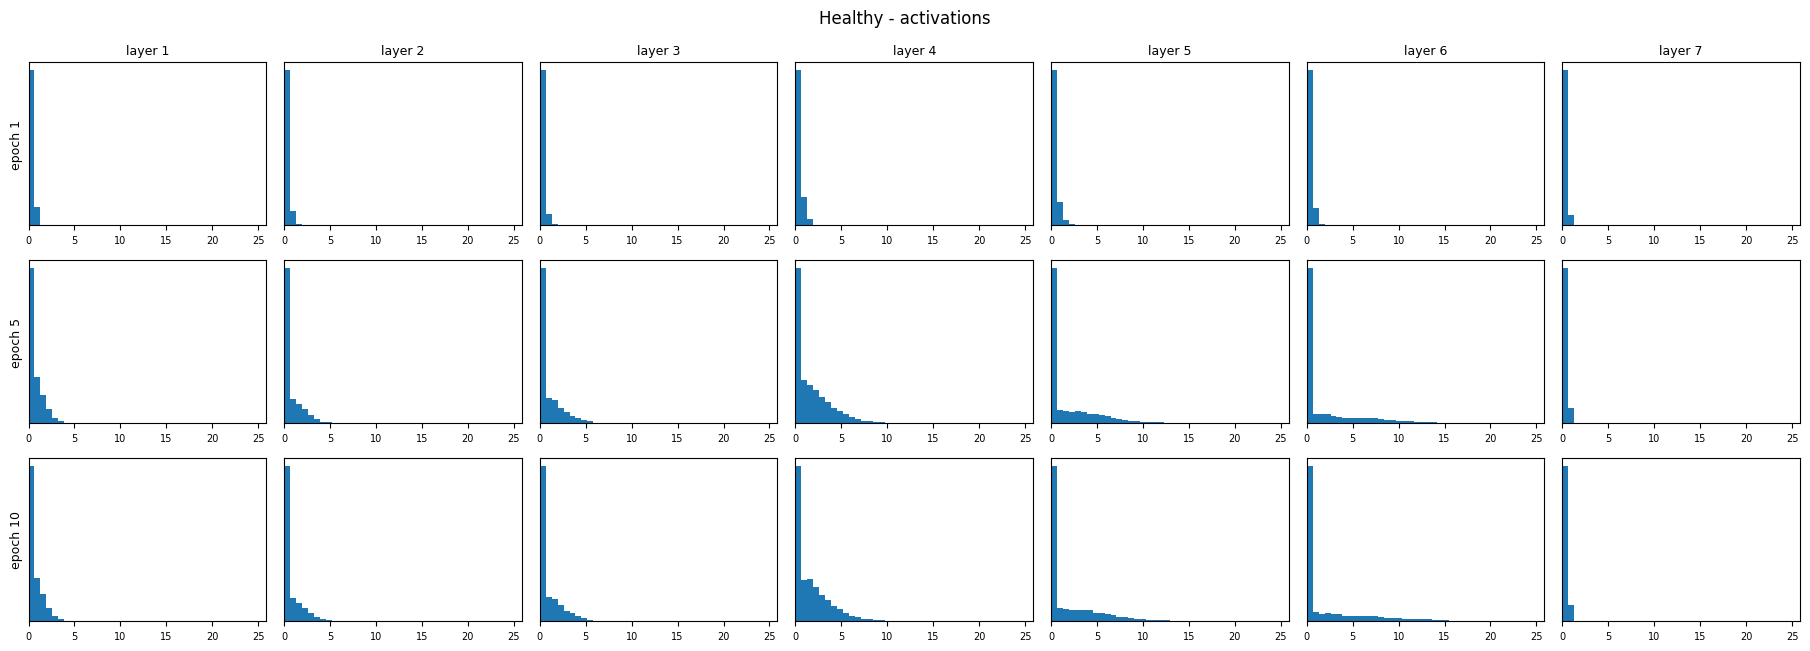

In [32]:
plot_histograms(healthy_history, "gradients", title="Healthy - weight gradients", save_path=PLOTS + "healthy_gradients.png")
plot_histograms(healthy_history, "activations", title="Healthy - activations", save_path=PLOTS + "healthy_activations.png")

## tamanho do gradiente por camada

Com sigmoid o gradiente cai 10× por camada. com ReLU + He fica parecido em todas.

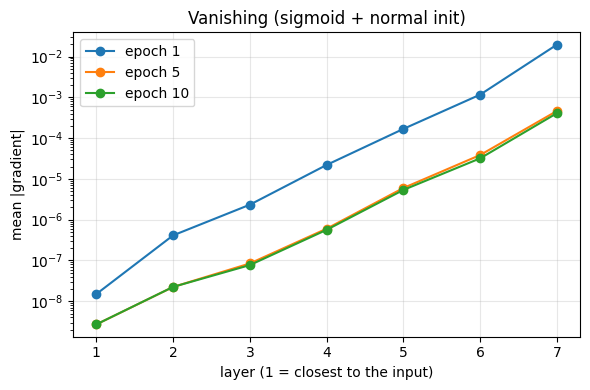

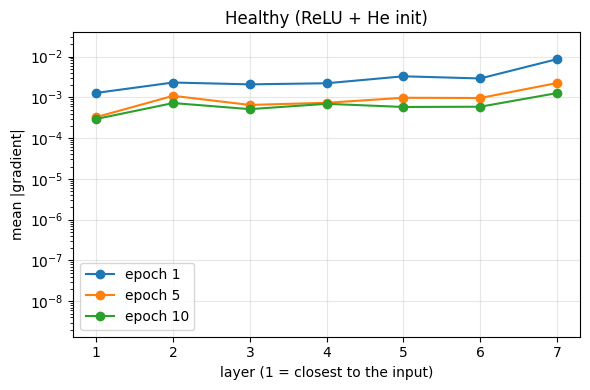

In [34]:
all_sizes = [np.mean(np.abs(g)) for h in (vanishing_history, healthy_history)
             for snapshot in h["snapshots"] for g in snapshot["gradients"]]
GRAD_YLIM = (min(all_sizes) / 2, max(all_sizes) * 2)

plot_gradient_sizes(vanishing_history, title="Vanishing (sigmoid + normal init)", save_path=PLOTS + "vanishing_gradient_sizes.png", ylim=GRAD_YLIM)
plot_gradient_sizes(healthy_history, title="Healthy (ReLU + He init)", save_path=PLOTS + "healthy_gradient_sizes.png", ylim=GRAD_YLIM)